# PBL JS14 - CNN Level Karakter untuk URL

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js14-convolutional-neural-network)

Notebook ini menerapkan langkah-langkah jobsheet JS14 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS14 | Penerapan pada URL |
| --- | --- |
| Praktikum 1 - langkah CNN: preprocessing, Conv, Pool, Flatten, Dense, compile, fit, prediksi satu sampel | CNN `Conv1D` pada urutan karakter URL |
| Praktikum 2 - CNN multikelas (10 kelas CIFAR) | Klasifikasi 7 kelas `type` |
| Tugas - modifikasi model untuk akurasi lebih tinggi | Arsitektur multi-kernel + global max pooling (eXpose/Kim) |
| Catatan dosen - CNN untuk data teks | URL diperlakukan sebagai teks level karakter |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


URL tidak memiliki "kata" yang baku: nama domain acak, path berisi angka, dan parameter query. Karena itu CNN diterapkan pada **level karakter**
seperti eXpose (Saxe & Berlin, 2017) dan cabang karakter URLNet (Le dkk., 2018). Setiap karakter menjadi indeks, di-embed,
lalu `Conv1D` mempelajari pola n-gram karakter seperti `.php?`, `/bins/`, atau `paypal-`.

## Langkah 1-2 - Import dan pra-pengolahan (karakter → indeks, padding)

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
tf.keras.utils.set_random_seed(42)
df = pbl_url.load_urls()
lengths = df['url'].str.len()
print('Panjang URL: median', lengths.median(), '| persentil 95', lengths.quantile(.95), '| persentil 99', lengths.quantile(.99))
MAXLEN = 200
chars = sorted(set(''.join(df['url'].sample(200000, random_state=0))))
char_index = {c: i + 2 for i, c in enumerate(chars)}   # 0 = padding, 1 = karakter tak dikenal
VOCAB = len(char_index) + 2
def encode(urls):
    out = np.zeros((len(urls), MAXLEN), dtype=np.int32)
    for i, u in enumerate(urls):
        ids = [char_index.get(c, 1) for c in u[:MAXLEN]]
        out[i, :len(ids)] = ids
    return out
le = LabelEncoder().fit(pbl_url.CLASSES); y = le.transform(df['type'])
X = encode(df['url'].tolist())
X_tmp, X_te, y_tmp, y_te, u_tmp, u_te = train_test_split(X, y, df['url'].to_numpy(), test_size=0.2, stratify=y, random_state=42)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.1, stratify=y_tmp, random_state=42)
print('Vocab karakter:', VOCAB, '| train/val/test:', len(X_tr), len(X_va), len(X_te), f'| {100 * (lengths > MAXLEN).mean():.2f}% URL dipotong')

Panjang URL: median 44.0 | persentil 95 133.0 | persentil 99 240.0


Vocab karakter: 276 | train/val/test: 564267 62697 156741 | 1.69% URL dipotong


## Langkah 3 - Model CNN layer demi layer (pola Praktikum 1/2: Conv → Pool → Conv → Pool → Flatten → Dense)

In [3]:
cnn = models.Sequential([
    layers.Input(shape=(MAXLEN,)),
    layers.Embedding(VOCAB, 32),
    layers.Conv1D(64, 5, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 5, activation='relu'),
    layers.MaxPooling1D(2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(le.classes_), activation='softmax'),
])
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 32)        │         8,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 196, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 98, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 94, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 47, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3008)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       385,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 425,735 (1.62 MB)

 Trainable params: 425,735 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

## Langkah 4 - Fit CNN

In [4]:
t0 = time.perf_counter()
h1 = cnn.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=5, batch_size=256, verbose=2)
t_cnn = time.perf_counter() - t0
p_cnn = cnn.predict(X_te, batch_size=4096, verbose=0).argmax(1)
print(f'Waktu latih {t_cnn / 60:.1f} menit | test acc={accuracy_score(y_te, p_cnn):.4f}, macro-F1={f1_score(y_te, p_cnn, average="macro"):.4f}')

Epoch 1/5


2205/2205 - 56s - 26ms/step - accuracy: 0.8139 - loss: 0.4828 - val_accuracy: 0.8607 - val_loss: 0.3676


Epoch 2/5


2205/2205 - 60s - 27ms/step - accuracy: 0.8739 - loss: 0.3319 - val_accuracy: 0.8772 - val_loss: 0.3208


Epoch 3/5


2205/2205 - 62s - 28ms/step - accuracy: 0.8893 - loss: 0.2883 - val_accuracy: 0.8866 - val_loss: 0.2972


Epoch 4/5


2205/2205 - 62s - 28ms/step - accuracy: 0.8988 - loss: 0.2627 - val_accuracy: 0.8887 - val_loss: 0.2928


Epoch 5/5


2205/2205 - 62s - 28ms/step - accuracy: 0.9047 - loss: 0.2459 - val_accuracy: 0.8914 - val_loss: 0.2905


Waktu latih 5.0 menit | test acc=0.8902, macro-F1=0.7432


## Tugas - Modifikasi: multi-kernel + global max pooling (gaya eXpose / Kim)

In [5]:
tf.keras.utils.set_random_seed(42)
inp = layers.Input(shape=(MAXLEN,))
emb = layers.Embedding(VOCAB, 32)(inp)
branches = [layers.GlobalMaxPooling1D()(layers.Conv1D(128, k, activation='relu', padding='same')(emb)) for k in (2, 3, 4, 5)]
x = layers.Dropout(0.3)(layers.Dense(256, activation='relu')(layers.Concatenate()(branches)))
x = layers.Dropout(0.3)(layers.Dense(64, activation='relu')(x))
expose = models.Model(inp, layers.Dense(len(le.classes_), activation='softmax')(x))
expose.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
t0 = time.perf_counter()
h2 = expose.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=10, batch_size=256, callbacks=[es], verbose=2)
t_exp = time.perf_counter() - t0
proba = expose.predict(X_te, batch_size=4096, verbose=0); p_exp = proba.argmax(1)
print(f'{expose.count_params():,} parameter, {len(h2.history["loss"])} epoch, {t_exp / 60:.1f} menit | '
      f'test acc={accuracy_score(y_te, p_exp):.4f}, macro-F1={f1_score(y_te, p_exp, average="macro"):.4f}')

Epoch 1/10


2205/2205 - 169s - 77ms/step - accuracy: 0.8287 - loss: 0.4607 - val_accuracy: 0.8731 - val_loss: 0.3364


Epoch 2/10


2205/2205 - 168s - 76ms/step - accuracy: 0.8820 - loss: 0.3232 - val_accuracy: 0.8876 - val_loss: 0.2947


Epoch 3/10


2205/2205 - 170s - 77ms/step - accuracy: 0.8942 - loss: 0.2894 - val_accuracy: 0.8917 - val_loss: 0.2837


... (9 outputs left out)

2205/2205 - 177s - 80ms/step - accuracy: 0.9144 - loss: 0.2308 - val_accuracy: 0.9073 - val_loss: 0.2460


Epoch 9/10


2205/2205 - 173s - 78ms/step - accuracy: 0.9164 - loss: 0.2248 - val_accuracy: 0.9066 - val_loss: 0.2470


214,919 parameter, 9 epoch, 25.8 menit | test acc=0.9064, macro-F1=0.7033


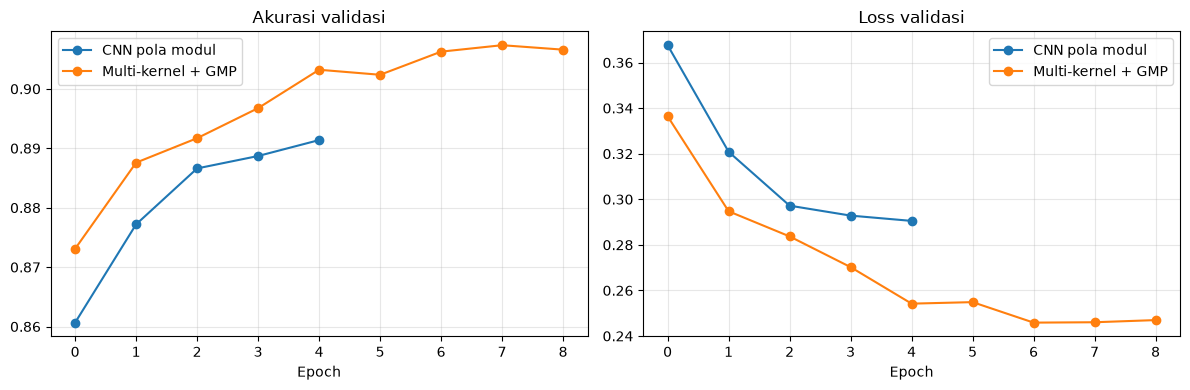

              precision    recall  f1-score   support

     Exploit     1.0000    0.2653    0.4194        49
      benign     0.9143    0.9361    0.9251     85286
  defacement     0.9479    0.9809    0.9641     19053
  legitimate     0.5321    0.0998    0.1681      1162
     malware     0.9794    0.8565    0.9138      4718
    phishing     0.8678    0.8513    0.8595     45923
        spam     0.9596    0.5182    0.6730       550

    accuracy                         0.9064    156741
   macro avg     0.8859    0.6440    0.7033    156741
weighted avg     0.9041    0.9064    0.9036    156741



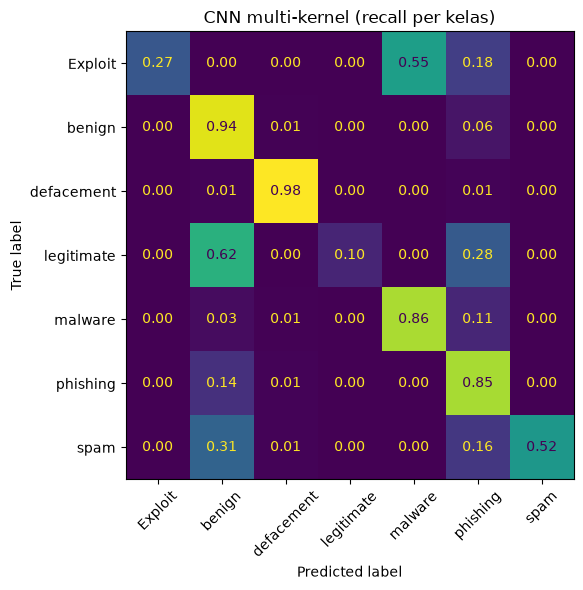

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [('CNN pola modul', h1), ('Multi-kernel + GMP', h2)]:
    ax[0].plot(h.history['val_accuracy'], marker='o', label=name); ax[1].plot(h.history['val_loss'], marker='o', label=name)
ax[0].set_title('Akurasi validasi'); ax[1].set_title('Loss validasi')
for a in ax: a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(classification_report(y_te, p_exp, target_names=le.classes_, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_te, p_exp, display_labels=le.classes_, normalize='true', values_format='.2f', ax=ax, colorbar=False, xticks_rotation=45)
plt.title('CNN multi-kernel (recall per kelas)'); plt.tight_layout(); plt.show()

## Langkah 5 - Prediksi satu URL

In [7]:
examples = ['google.com/search?q=machine+learning', 'paypal-account-verify.secure-login.xyz/webscr?cmd=update',
            '185.244.25.10/bins/mirai.arm7', 'sekolahku.sch.id/index.php?option=com_content&view=article&id=12&itemid=5',
            'github.com/404gh0st/machine-learning-smt-5']
p = expose.predict(encode(examples), verbose=0)
for u, row in zip(examples, p):
    top = row.argsort()[::-1][:2]
    print(f'{le.classes_[top[0]]:11s} {row[top[0]]:.3f} | {le.classes_[top[1]]:11s} {row[top[1]]:.3f} | {u}')

benign      0.988 | phishing    0.009 | google.com/search?q=machine+learning
benign      0.583 | phishing    0.415 | paypal-account-verify.secure-login.xyz/webscr?cmd=update
phishing    0.875 | malware     0.084 | 185.244.25.10/bins/mirai.arm7
defacement  0.925 | benign      0.049 | sekolahku.sch.id/index.php?option=com_content&view=article&id=12&itemid=5
benign      0.733 | phishing    0.236 | github.com/404gh0st/machine-learning-smt-5


## Perbandingan dengan baseline non-deep learning

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
t0 = time.perf_counter()
u_tr_all = u_tmp
vec = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=3, max_features=500000, sublinear_tf=True, dtype=np.float32)
lsvc = LinearSVC(C=0.5).fit(vec.fit_transform(u_tr_all), y_tmp); p_svm = lsvc.predict(vec.transform(u_te)); t_svm = time.perf_counter() - t0
comp = pd.DataFrame([
    {'model': 'TF-IDF char 3-5 + LinearSVC', 'test_acc': accuracy_score(y_te, p_svm), 'macro_F1': f1_score(y_te, p_svm, average='macro'), 'waktu_latih_menit': t_svm / 60},
    {'model': 'CNN pola modul (Conv-Pool-Conv-Pool-Flatten)', 'test_acc': accuracy_score(y_te, p_cnn), 'macro_F1': f1_score(y_te, p_cnn, average='macro'), 'waktu_latih_menit': t_cnn / 60},
    {'model': 'CNN multi-kernel + global max pooling', 'test_acc': accuracy_score(y_te, p_exp), 'macro_F1': f1_score(y_te, p_exp, average='macro'), 'waktu_latih_menit': t_exp / 60},
]).set_index('model'); comp.round(4)

,test_acc,macro_F1,waktu_latih_menit
model,,,
TF-IDF char 3-5 + LinearSVC,0.9375,0.8263,2.0844
CNN pola modul (Conv-Pool-Conv-Pool-Flatten),0.8902,0.7432,5.0456
CNN multi-kernel + global max pooling,0.9064,0.7033,25.7773


## Analisis

| Model | Parameter | Test acc | Macro-F1 | Waktu latih |
| --- | --- | --- | --- | --- |
| **TF-IDF n-gram karakter 3-5 + LinearSVC** | 500 ribu fitur | **0,938** | **0,826** | **2,1 menit** |
| CNN pola modul (Conv-Pool-Conv-Pool-Flatten), 5 epoch | 425.735 | 0,890 | 0,743 | 5,0 menit |
| CNN multi-kernel + global max pooling, 9 epoch (EarlyStopping) | 214.919 | 0,906 | 0,703 | 25,8 menit |
| *(pembanding PBL JS13: MLP 256-128 pada 28 fitur leksikal)* | 41.223 | 0,818 | 0,641 | 0,2 menit |

* **CNN berhasil mempelajari fitur langsung dari karakter.** Kedua CNN mengungguli MLP pada 28 fitur leksikal buatan tangan: accuracy naik 7-9 poin dan macro-F1 6-10 poin. Hasil ini sejalan dengan klaim eXpose (Saxe & Berlin, 2017) dan URLNet (Le dkk., 2018) bahwa CNN level karakter dapat menggantikan rekayasa fitur manual. Contohnya, URL Joomla `sekolahku.sch.id/index.php?option=com_content...` dikenali sebagai defacement (0,925), dan `google.com/search?...` sebagai benign (0,988).
* **Modifikasi multi-kernel (Tugas) menaikkan accuracy tetapi menurunkan macro-F1.** Accuracy naik 0,890 → 0,906 dan F1 benign, defacement, serta phishing meningkat. Namun recall Exploit turun ke 0,27 dan legitimate 0,10, sehingga macro-F1 turun 0,743 → 0,703. Global max pooling hanya mengambil sinyal terkuat per filter, sehingga detail **posisi** hilang, misalnya "diawali alamat IP" yang menjadi ciri Exploit. Ini terlihat pada contoh `185.244.25.10/bins/mirai.arm7`, yang diprediksi **phishing (0,875)** oleh CNN multi-kernel tetapi benar sebagai malware oleh MLP leksikal (PBL JS15, 0,973). Dengan hanya 175 contoh Exploit di data latih, CNN tidak cukup belajar pola kelas ini. Untuk kelas sangat langka, fitur eksplisit seperti `is_ip` masih lebih efektif.
* **Baseline linier tetap terbaik.** TF-IDF n-gram karakter + LinearSVC lebih akurat (+3,1 poin accuracy, +8 poin macro-F1) dan 12× lebih cepat dilatih daripada CNN multi-kernel di CPU. Temuan ini sama dengan PBL JS11 dan eksperimen teks JS14. Zhang dkk. (2015) menunjukkan bahwa n-gram TF-IDF bersaing dengan CNN karakter sampai ratusan ribu sampel. Le dkk. (2018) menunjukkan bahwa URLNet baru unggul dengan menggabungkan cabang karakter **dan** kata, dilatih pada jutaan URL. Dengan 564 ribu URL, 5-9 epoch, dan tanpa GPU, CNN di sini belum mencapai titik itu. Akurasi validasi CNN pola modul masih naik pada epoch ke-5 (0,8887 → 0,8914), sehingga pelatihan lebih lama kemungkinan masih membantu model tersebut.
* **Kegagalan bersama.** Ketiga model hampir tidak mampu mengenali `legitimate` (recall ≤ 0,18). Kelas ini adalah domain tanpa path yang secara leksikal identik dengan benign (PBL JS02), sehingga yang diperlukan adalah perbaikan data atau penggabungan kelas, bukan arsitektur model yang lebih rumit. URL phishing buatan `paypal-account-verify.secure-login.xyz/...` juga diprediksi benign (0,583), padahal TF-IDF/MLP leksikal mengenalinya. Untuk sistem nyata, *ensemble* CNN karakter dengan model n-gram dan fitur leksikal lebih aman.

## Rujukan

1. Saxe, J., & Berlin, K. (2017). eXpose: A character-level convolutional neural network with embeddings for detecting malicious URLs, file paths and registry keys. *arXiv:1702.08568*. https://arxiv.org/abs/1702.08568
2. Le, H., Pham, Q., Sahoo, D., & Hoi, S. C. H. (2018). URLNet: Learning a URL representation with deep learning for malicious URL detection. *arXiv:1802.03162*. https://arxiv.org/abs/1802.03162
3. Zhang, X., Zhao, J., & LeCun, Y. (2015). Character-level convolutional networks for text classification. *Advances in Neural Information Processing Systems 28 (NeurIPS)*, 649-657.
4. Kim, Y. (2014). Convolutional neural networks for sentence classification. *Proceedings of EMNLP 2014*, 1746-1751. https://doi.org/10.3115/v1/D14-1181
5. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153
6. Sahoo, D., Liu, C., & Hoi, S. C. H. (2017). Malicious URL detection using machine learning: A survey. *arXiv:1701.07179*. https://arxiv.org/abs/1701.07179
7. He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering*, 21(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239